# CoAT: prediction by complexity minimization

Three implementations of the CoAT classifier (Complexity-based Analogical Transfer), which all predict the same class:

1. **Naive**, O(n³) per candidate: count similarity inversions over all triplets of the extended case base.
2. **O(n²)**: only the triplets containing the new point change from one candidate to another, so only those are counted.
3. **Vectorized PyTorch**: the O(n²) computation written as tensor operations, for a batch of query points, on GPU when available.

The notebook checks that the three versions give the same predictions, then compares their running times.

In [1]:
# Naive and O(n²) versions

import numpy as np

def similarity_X(x1, x2):
    """Similarity between situations: 1 / (1 + Euclidean distance)."""
    norm = np.sqrt((x2[0] - x1[0])**2 + (x2[1] - x1[1])**2)
    return 1 / (1 + norm)

def similarity_Y(y1, y2) -> int:
    """Similarity between outcomes: 1 if identical, 0 otherwise."""
    return int(y1 == y2)

def evaluate_triplet_inversion(zi, zj, zk) -> int:
    """1 if the triplet (i, j, k) is a similarity inversion, 0 otherwise."""
    simX_i_j = similarity_X(zi[0], zj[0])
    simY_i_j = similarity_Y(zi[1], zj[1])
    simX_i_k = similarity_X(zi[0], zk[0])
    simY_i_k = similarity_Y(zi[1], zk[1])
    return int(simX_i_j >= simX_i_k and simY_i_j < simY_i_k)

def compute_complexity(data) -> int:
    """Naive O(n³) complexity: inversions over all triplets of data."""
    n = len(data)
    return sum(evaluate_triplet_inversion(data[i], data[j], data[k])
               for i in range(n) for j in range(n) for k in range(n))

def coat_predict(x_new, CB, ys_unique):
    """Predicts the outcome that minimizes the complexity of CB ∪ {(x_new, y)}."""
    scores = [compute_complexity(CB + [(x_new, y)]) for y in ys_unique]
    return ys_unique[scores.index(min(scores))]

def compute_complexity_optimized(CB, z_new) -> int:
    """Inversions over the triplets containing z_new, in O(n²).
    Triplets without z_new contribute the same amount for every candidate,
    so they can be ignored without changing the argmin. The triplet (z, z, z) is always 0."""
    n = len(CB)
    cmp = 0
    for i in range(n):
        for j in range(n):
            cmp += evaluate_triplet_inversion(z_new, CB[i], CB[j])
            cmp += evaluate_triplet_inversion(CB[i], z_new, CB[j])
            cmp += evaluate_triplet_inversion(CB[i], CB[j], z_new)
    for i in range(n):
        cmp += evaluate_triplet_inversion(z_new, z_new, CB[i])
        cmp += evaluate_triplet_inversion(z_new, CB[i], z_new)
        cmp += evaluate_triplet_inversion(CB[i], z_new, z_new)
    return cmp

def coat_predict_optimized(x_new, CB, ys_unique):
    """Same prediction as coat_predict, in O(n²) per candidate."""
    scores = [compute_complexity_optimized(CB, (x_new, y)) for y in ys_unique]
    return ys_unique[scores.index(min(scores))]

## Data generation

In [2]:
import random
import math
import timeit
import matplotlib.pyplot as plt

def random_point_in_disk(x, y, r):
    """Point drawn uniformly in the disk of center (x, y) and radius r."""
    theta = random.uniform(0, 2 * math.pi)
    rho = math.sqrt(random.uniform(0, 1)) * r  # square root: uniform density over the disk
    return (x + rho * math.cos(theta), y + rho * math.sin(theta))

def case_base(x1, y1, r1, label1, n1, x2, y2, r2, label2, n2):
    """Case base: n1 points of class label1 and n2 points of class label2."""
    CB = [(random_point_in_disk(x1, y1, r1), label1) for _ in range(n1)]
    CB += [(random_point_in_disk(x2, y2, r2), label2) for _ in range(n2)]
    return CB

## Check: naive and O(n²) give the same predictions

For each candidate, the naive complexity of CB ∪ {z} equals the complexity of CB (the same for every candidate) plus the number of inversions in the triplets containing z. We check this exact identity, then that the predictions match.

In [3]:
random.seed(0)
labels = ["red", "blue"]
n_tests = 0
for _ in range(5):
    CB = case_base(-1.5, 0, 2, "red", 12, 1.5, 0, 2, "blue", 12)
    base = compute_complexity(CB)
    for _ in range(10):
        q = random_point_in_disk(0, 0, 4)
        for y in labels:
            assert compute_complexity(CB + [(q, y)]) - base == compute_complexity_optimized(CB, (q, y))
        assert coat_predict(q, CB, labels) == coat_predict_optimized(q, CB, labels)
        n_tests += 1
print(f"OK: {n_tests} identical predictions, scores equal up to the constant")

OK: 50 identical predictions, scores equal up to the constant


## Running time: naive vs O(n²)

In [4]:
CB = case_base(3, 3, 1, "red", 50, -3, -3, 1, "blue", 50)
ys = ["red", "blue"]
point_test = (1, 1)

n1, n2 = 1, 10  # the naive version is slow: timed on a single call
time1 = timeit.timeit(lambda: coat_predict(point_test, CB, ys), number=n1) / n1
time2 = timeit.timeit(lambda: coat_predict_optimized(point_test, CB, ys), number=n2) / n2

print(f"Case base of {len(CB)} points")
print(f"coat_predict           : {time1:.3f} s per call")
print(f"coat_predict_optimized : {time2:.3f} s per call (mean over {n2} calls)")
print(f"Speedup: x{time1 / time2:.1f}")

Case base of 100 points
coat_predict           : 8.072 s per call
coat_predict_optimized : 0.255 s per call (mean over 10 calls)
Speedup: x31.6


## Prediction example

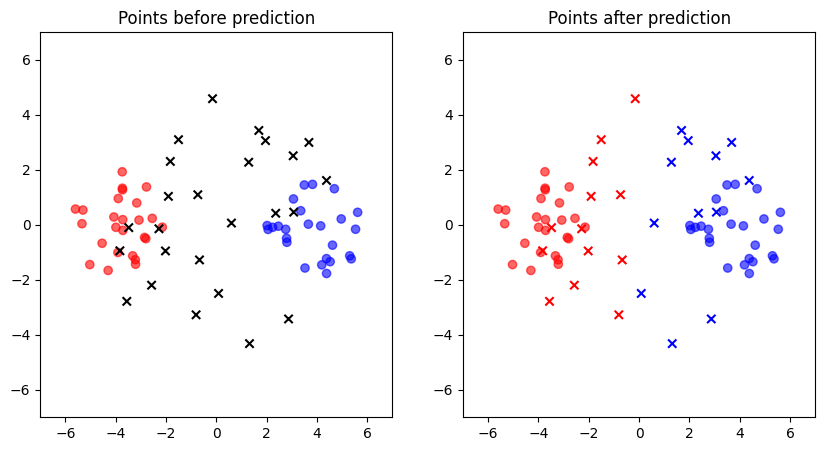

In [5]:
random.seed(1)
CB = case_base(-4, 0, 2, "red", 25, 4, 0, 2, "blue", 25)
set_class = ["red", "blue"]
queries = [random_point_in_disk(0, 0, 5) for _ in range(25)]

# Predictions use only the labeled case base CB
predictions = [coat_predict_optimized(q, CB, set_class) for q in queries]

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, colors, title in [(axes[0], ["black"] * len(queries), "Points before prediction"),
                            (axes[1], predictions, "Points after prediction")]:
    (x, y), lab = zip(*[p for p, _ in CB]), [l for _, l in CB]
    ax.scatter(x, y, color=lab, alpha=0.6)
    ax.scatter(*zip(*queries), color=colors, marker="x")
    ax.set_xlim(-7, 7); ax.set_ylim(-7, 7); ax.set_title(title)
plt.show()

## Running time of the O(n²) version vs case base size

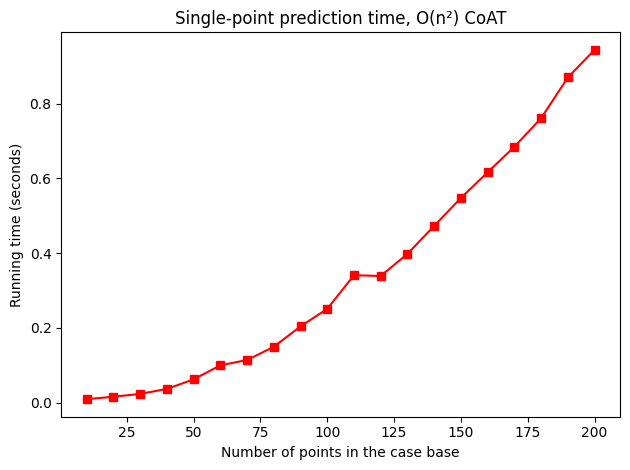

In [6]:
point_test = (1, 1)
ys = ["red", "blue"]
sizes, times = [], []
for i in range(1, 21):
    CB = case_base(3, 3, 1, "red", i * 5, -3, -3, 1, "blue", i * 5)
    sizes.append(len(CB))
    times.append(timeit.timeit(lambda: coat_predict_optimized(point_test, CB, ys), number=1))

plt.plot(sizes, times, marker="s", color="red")
plt.xlabel("Number of points in the case base")
plt.ylabel("Running time (seconds)")
plt.title("Single-point prediction time, O(n²) CoAT")
plt.tight_layout()
plt.show()

## Vectorized PyTorch version

Same triplets as the O(n²) version, computed for p query points at once:
- (z, j, k): the new point as the reference;
- (i, z, k) and (i, j, z): the new point in second or third position, which also needs the similarities within the case base;
- (z, i, z): the only triplet with two z's that can count (a case at the same location with another class). The others are always 0.

Coordinates and classes are separate tensors, so the class never enters the distance.

In [7]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device)

def sim_x(A, B):
    """Similarity between situations, same as the Python version: 1 / (1 + distance)."""
    return 1 / (1 + torch.cdist(A, B, compute_mode="donot_use_mm_for_euclid_dist"))

def sim_y(a, b):
    """Similarity between classes: 1 if identical, 0 otherwise."""
    return (a[:, None] == b[None, :]).float()

def compute_incompatibility(T_X, t_y, CB_X, CB_y):
    """Inversions over all triplets containing the new point, for each row of T_X.

    T_X: (p, d) query points, t_y: (p,) candidate class
    CB_X: (N, d) case base, CB_y: (N,) classes
    """
    sx, sy = sim_x(T_X, CB_X), sim_y(t_y, CB_y)        # (p, N)
    sxc, syc = sim_x(CB_X, CB_X), sim_y(CB_y, CB_y)    # (N, N)
    # (z, j, k): new point in first position
    a = ((sx[:, :, None] >= sx[:, None, :]) & (sy[:, :, None] < sy[:, None, :])).sum((1, 2))
    # (i, z, k): new point in second position
    b = ((sx[:, :, None] >= sxc[None]) & (sy[:, :, None] < syc[None])).sum((1, 2))
    # (i, j, z): new point in third position
    c = ((sxc[None] >= sx[:, :, None]) & (syc[None] < sy[:, :, None])).sum((1, 2))
    # (z, i, z): a case at the same location with another class
    d = ((sx >= 1) & (sy < 1)).sum(1)
    return a + b + c + d

def predict_COAT(T_X, CB_X, CB_y, Q):
    """Class (between 0 and Q-1) that minimizes the incompatibility, for each row of T_X."""
    p = T_X.shape[0]
    scores = torch.stack([
        compute_incompatibility(T_X, torch.full((p,), c, dtype=CB_y.dtype, device=T_X.device), CB_X, CB_y)
        for c in range(Q)
    ], dim=1)
    return scores.argmin(dim=1)

def to_tensors(CB, labels, dtype=torch.float64):
    """Converts a Python case base into (coordinates, classes) tensors on the device."""
    X = torch.tensor([p for p, _ in CB], dtype=dtype, device=device)
    y = torch.tensor([labels.index(l) for _, l in CB], device=device)
    return X, y

Device : cuda


## Check: PyTorch gives the same predictions as the Python versions

In [8]:
random.seed(0)
labels = ["red", "blue"]
n_tests = 0
for _ in range(5):
    CB = case_base(-1.5, 0, 2, "red", 20, 1.5, 0, 2, "blue", 20)
    X, y = to_tensors(CB, labels)
    queries = [random_point_in_disk(0, 0, 4) for _ in range(20)]
    T = torch.tensor(queries, dtype=torch.float64, device=device)
    torch_preds = predict_COAT(T, X, y, len(labels)).tolist()
    for q, p in zip(queries, torch_preds):
        assert coat_predict_optimized(q, CB, labels) == labels[p]
        n_tests += 1
print(f"OK: {n_tests} identical predictions between PyTorch and Python")

OK: 100 identical predictions between PyTorch and Python


## Comparison of the three versions on a single point

Same case base and same query point for all three versions. The first PyTorch call (GPU warm-up) is not timed.

In [9]:
def timed(f, number):
    """Mean time per call, waiting for GPU work to finish."""
    if device.type == "cuda":
        torch.cuda.synchronize()
    start = time.perf_counter()
    for _ in range(number):
        f()
    if device.type == "cuda":
        torch.cuda.synchronize()
    return (time.perf_counter() - start) / number

import time
random.seed(2)
labels = ["red", "blue"]
CB = case_base(3, 3, 1, "red", 50, -3, -3, 1, "blue", 50)
point_test = (1, 1)
X, y = to_tensors(CB, labels, dtype=torch.float32)
T = torch.tensor([point_test], dtype=torch.float32, device=device)

predict_COAT(T, X, y, 2)  # warm-up
t_naive = timed(lambda: coat_predict(point_test, CB, labels), 1)
t_opt = timed(lambda: coat_predict_optimized(point_test, CB, labels), 10)
t_torch = timed(lambda: predict_COAT(T, X, y, 2), 100)

print(f"Case base of {len(CB)} points, 1 query point, device = {device}")
print(f"Naive     : {t_naive:.4f} s")
print(f"O(n²)     : {t_opt:.4f} s  (x{t_naive / t_opt:.0f} vs naive)")
print(f"PyTorch   : {t_torch:.6f} s  (x{t_opt / t_torch:.0f} vs O(n²), x{t_naive / t_torch:.0f} vs naive)")

Case base of 100 points, 1 query point, device = cuda
Naive     : 7.9956 s
O(n²)     : 0.2410 s  (x33 vs naive)
PyTorch   : 0.003572 s  (x67 vs O(n²), x2238 vs naive)


## PyTorch: time to predict 100 points vs case base size

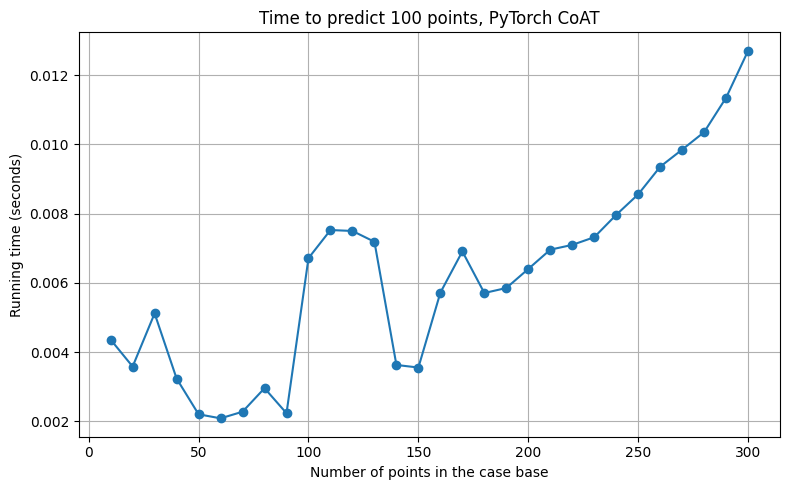

In [10]:
Q, d, p = 2, 2, 100
T_X = torch.cat([torch.randn(p // 2, d) * 0.2,
                 torch.randn(p - p // 2, d) * 0.2 + 3.0]).to(device)

base_sizes = list(range(10, 301, 10))
durations = []
for base_size in base_sizes:
    n, m = base_size // 2, base_size - base_size // 2
    CB_X = torch.cat([torch.randn(n, d) * 0.2, torch.randn(m, d) * 0.2 + 3.0]).to(device)
    CB_y = torch.cat([torch.zeros(n, dtype=torch.long), torch.ones(m, dtype=torch.long)]).to(device)
    durations.append(timed(lambda: predict_COAT(T_X, CB_X, CB_y, Q), 3))

plt.figure(figsize=(8, 5))
plt.plot(base_sizes, durations, marker="o")
plt.title("Time to predict 100 points, PyTorch CoAT")
plt.xlabel("Number of points in the case base")
plt.ylabel("Running time (seconds)")
plt.grid(True)
plt.tight_layout()
plt.show()

## Running time vs case base size and number of query points

Memory grows as p × N² (comparison tensors): reduce the sizes if the GPU runs out of memory.

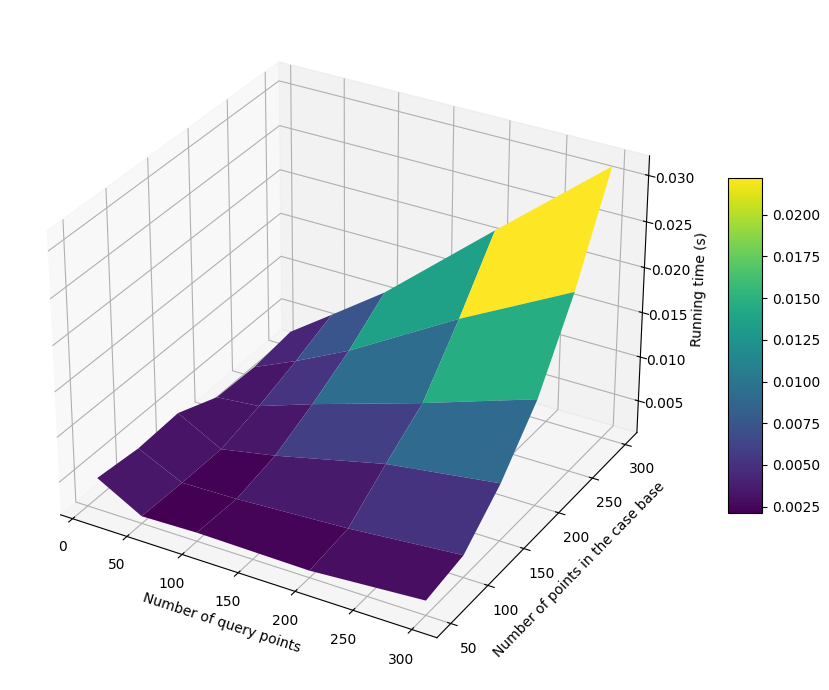

In [11]:
import numpy as np

predict_sizes = [10, 50, 100, 200, 300]
base_sizes = [50, 100, 150, 200, 250, 300]
Z = np.zeros((len(predict_sizes), len(base_sizes)))

for i, pred_size in enumerate(predict_sizes):
    T_X = torch.cat([torch.randn(pred_size // 2, d) * 0.2,
                     torch.randn(pred_size - pred_size // 2, d) * 0.2 + 3.0]).to(device)
    for j, base_size in enumerate(base_sizes):
        n, m = base_size // 2, base_size - base_size // 2
        CB_X = torch.cat([torch.randn(n, d) * 0.2, torch.randn(m, d) * 0.2 + 3.0]).to(device)
        CB_y = torch.cat([torch.zeros(n, dtype=torch.long), torch.ones(m, dtype=torch.long)]).to(device)
        Z[i, j] = timed(lambda: predict_COAT(T_X, CB_X, CB_y, Q), 3)

Xg, Yg = np.meshgrid(predict_sizes, base_sizes, indexing="ij")
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")
surf = ax.plot_surface(Xg, Yg, Z, cmap="viridis")
ax.set_xlabel("Number of query points")
ax.set_ylabel("Number of points in the case base")
ax.set_zlabel("Running time (s)")
fig.colorbar(surf, shrink=0.5, aspect=10)
plt.tight_layout()
plt.show()